# Multi-LexSum: a story-driven exploratory analysis

**Dataset:** [allenai/multi_lexsum](https://huggingface.co/datasets/allenai/multi_lexsum) · config **`v20230518`**

This notebook walks from *“what is in the box?”* to *“what does this mean for legal summarization and citation verification?”* — aligned with a thesis on **dual-system, hallucination-aware legal document summarization** (generate → verify case citations → correct).

---

### How to run **locally** (recommended — uses your downloaded copy)

```bash
cd /path/to/Thesis/code
python3 -m venv .venv
source .venv/bin/activate
pip install -U pip && pip install -e .
pip install jupyter matplotlib seaborn tqdm transformers ipykernel
python -m ipykernel install --user --name=multilexsum-thesis --display-name "Python (multilexsum-thesis)"
jupyter notebook notebooks/multilexsum_eda.ipynb
```

In Cursor/VS Code: **Select Kernel → Python (multilexsum-thesis)** or `.venv/bin/python`.

**Requirements:** the full dataset must already be under **`code/data/`**:
- `data/hf/` — Arrow cache (~1.7 GB)
- `data/multilexsum/releases/v20230518/` — raw JSON (~2.1 GB)

The notebook auto-detects the `code/` root (folder with `pyproject.toml`), loads from **`data/hf/`**, and writes outputs to **`code/reports/`**. No Hugging Face re-download.

Optional CourtListener spot-check: `export COURTLISTENER_TOKEN=your_token` before starting Jupyter.

### How to run in **Google Colab** (optional)

1. Upload this notebook to Colab.
2. Run all cells — first run **re-downloads** from Hugging Face (~4.5 GB, ~15–30 min).
3. Colab Secrets: optional `HF_TOKEN`, `COURTLISTENER_TOKEN`.

---

### Story arc (what you will see)

1. First peek — schema, head, one full case  
2. Visual gallery — “what a case looks like” (text panels + charts)  
3. Corpus shape — splits, missing fields, duplicates  
4. Three summary granularities — tiny / short / long  
5. **What changes when you switch target granularity?**  
6. Multi-document sources — count, types, OCR  
7. Extreme length — validating the “75k+ word” claim & truncation risk  
8. Legal metadata landscape — case types, years, outcomes  
9. Citations in expert summaries — heuristics (+ optional CourtListener)  
10. Data quality & anomalies  
11. **So what?** — implications for summarization + verification pipeline  
12. Export figures/tables for your own slides

---

## 1 · Setup

We pin a random seed, find the project root (`code/`), and point at your local **`data/`** copy.

In [3]:
import os
import sys
import subprocess
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
print("Environment:", "Google Colab" if IN_COLAB else "Local")
print("Python:", sys.executable)


def find_code_root(start: Path) -> Path:
    for p in [start.resolve(), *start.resolve().parents]:
        if (p / "pyproject.toml").is_file() and (p / "data").is_dir():
            return p
    raise RuntimeError(
        "Could not find code/ root. Open from Thesis/code/notebooks/ and ensure code/data/ exists."
    )


def ensure_project_deps() -> None:
    """Install pip packages into the active Jupyter kernel (no multilexsum import)."""
    pkgs = [
        "datasets>=2.16,<4", "pyarrow", "huggingface_hub",
        "matplotlib", "seaborn", "tqdm", "transformers", "pandas", "numpy",
    ]
    need = importlib.util.find_spec("datasets") is None
    if need:
        print("Installing dependencies into this kernel (one-time)…")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
    if importlib.util.find_spec("datasets") is None:
        raise RuntimeError(
            f"'datasets' still missing. Kernel: {sys.executable}\n"
            "Select kernel: .venv/bin/python"
        )


if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "datasets", "pandas", "matplotlib", "seaborn", "tqdm", "transformers",
    ])
    WORK = Path("/content/multilexsum_eda")
    WORK.mkdir(parents=True, exist_ok=True)
    os.chdir(WORK)
    CODE_ROOT = WORK
    DATA_DIR = WORK / "data"
    HF_CACHE = DATA_DIR / "hf"
    TOKEN_SUBSAMPLE = 800
else:
    CODE_ROOT = find_code_root(Path.cwd())
    ensure_project_deps()
    WORK = CODE_ROOT
    os.chdir(WORK)
    DATA_DIR = CODE_ROOT / "data"
    HF_CACHE = DATA_DIR / "hf"
    RAW_RELEASE = DATA_DIR / "multilexsum" / "releases" / "v20230518"
    # Default: subsample truncation (800/split) for practical runtime. Full audit: os.environ["EDA_FAST"] = "0"
    FAST_MODE = os.environ.get("EDA_FAST", "1") != "0"
    TOKEN_SUBSAMPLE = 800 if FAST_MODE else None
    if not HF_CACHE.is_dir():
        raise FileNotFoundError(f"Missing local cache: {HF_CACHE}")
    print(f"Local HF cache: {HF_CACHE} ({len(list(HF_CACHE.glob('**/*.arrow')))} .arrow files)")
    if RAW_RELEASE.is_dir():
        print(f"Raw JSON: {RAW_RELEASE}")

import re
import textwrap
import json
import shutil
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, HTML, Markdown
from tqdm.auto import tqdm
from datasets import load_dataset

SEED = 42
RNG = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

REPORTS = WORK / "reports"
FIG = REPORTS / "figures"
TAB = REPORTS / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)
print("Working directory:", WORK.resolve())


Environment: Local
Python: /Users/rajakarthikchirumamilla/Desktop/Thesis/.venv/bin/python
Local HF cache: /Users/rajakarthikchirumamilla/Desktop/Thesis/code/data/hf (4 .arrow files)
Raw JSON: /Users/rajakarthikchirumamilla/Desktop/Thesis/code/data/multilexsum/releases/v20230518
Working directory: /Users/rajakarthikchirumamilla/Desktop/Thesis/code


In [4]:
CONFIG = "v20230518"
DATASET_ID = "allenai/multi_lexsum"

os.environ["MULTILEXSUM_CACHE"] = str(HF_CACHE)

if IN_COLAB:
    hf_token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    ds = load_dataset(
        DATASET_ID,
        name=CONFIG,
        trust_remote_code=True,
        token=hf_token,
    )
else:
    # load_dataset uses local Arrow cache in code/data/hf — no re-download
    ds = load_dataset(
        DATASET_ID,
        name=CONFIG,
        cache_dir=str(HF_CACHE),
        trust_remote_code=True,
    )
    from datetime import datetime, timezone

    manifest_path = DATA_DIR / "manifest.json"
    manifest = {
        "dataset": DATASET_ID,
        "config_name": CONFIG,
        "local_hf_cache_dir": str(HF_CACHE),
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "total_rows_all_splits": sum(len(ds[k]) for k in ds.keys()),
        "splits": {sn: {"name": sn, "num_rows": len(ds[sn])} for sn in ds.keys()},
    }
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print("Manifest:", manifest_path)

print("Splits:", {k: len(ds[k]) for k in ds.keys()})
TOTAL = sum(len(ds[k]) for k in ds.keys())
print("Total cases:", TOTAL)
assert TOTAL == 4539, f"Expected 4539 cases, got {TOTAL} — check local data copy"


def sources_metadata_rows(ex):
    """HF stores sources_metadata as columnar dict; normalize to list[dict]."""
    sm = ex.get("sources_metadata") or {}
    if isinstance(sm, list):
        return sm
    if not isinstance(sm, dict) or not sm:
        return []
    keys = list(sm.keys())
    lengths = [len(sm[k]) for k in keys if isinstance(sm.get(k), list)]
    n = max(lengths) if lengths else 0
    rows = []
    for i in range(n):
        rows.append({
            k: sm[k][i] if isinstance(sm.get(k), list) and i < len(sm[k]) else sm.get(k)
            for k in keys
        })
    return rows



Manifest: /Users/rajakarthikchirumamilla/Desktop/Thesis/code/data/manifest.json
Splits: {'train': 3177, 'validation': 454, 'test': 908}
Total cases: 4539


---

## 2 · First peek — schema, head, and one complete case

Multi-LexSum is **multi-document summarization** over U.S. civil-rights litigation: many long source PDFs/texts per case, plus **expert-written summaries** at up to three granularities.

In [5]:
ex0 = ds["train"][0]
print("Field keys:", sorted(ex0.keys()))
print()
for k, v in ex0.items():
    if k == "sources":
        print(f"  {k}: list of {len(v)} documents")
        for j, s in enumerate(v[:3]):
            print(f"    doc[{j}] chars={len(s or '')}")
    elif k == "sources_metadata":
        rows = sources_metadata_rows(ex0)
        print(f"  {k}: {len(rows)} metadata records")
        if rows and isinstance(rows[0], dict):
            print(f"    example keys: {list(rows[0].keys())}")
    elif k == "case_metadata":
        print(f"  {k}: {list(v.keys())[:8]}…")
    elif k.startswith("summary"):
        preview = (v or "")[:120].replace("\n", " ")
        print(f"  {k}: {len(v or '')} chars → {preview!r}…")
    else:
        print(f"  {k}: {v!r}")

# Flat "head" table (one row per case)
def flatten_row(split, idx):
    ex = ds[split][idx]
    cm = ex.get("case_metadata") or {}
    return {
        "split": split,
        "row": idx,
        "id": ex["id"],
        "case_name": cm.get("case_name", ""),
        "case_type": cm.get("case_type", ""),
        "n_sources": len(ex.get("sources") or []),
        "words_long": len((ex.get("summary/long") or "").split()),
        "words_short": len((ex.get("summary/short") or "").split()),
        "words_tiny": len((ex.get("summary/tiny") or "").split()),
    }

head_rows = [flatten_row("train", i) for i in range(5)]
tail_rows = [flatten_row("train", i) for i in range(len(ds["train"]) - 5, len(ds["train"]))]
head_df = pd.DataFrame(head_rows)
tail_df = pd.DataFrame(tail_rows)
print("\n=== HEAD (train, first 5) ===")
display(head_df)
print("=== TAIL (train, last 5) ===")
display(tail_df)


Field keys: ['case_metadata', 'id', 'sources', 'sources_metadata', 'summary/long', 'summary/short', 'summary/tiny']

  id: 'EE-AL-0045'
  sources: list of 4 documents
    doc[0] chars=5803
    doc[1] chars=7305
    doc[2] chars=12473
  sources_metadata: 4 metadata records
    example keys: ['doc_id', 'doc_type', 'doc_title', 'parser', 'is_ocr', 'url']
  summary/long: 1844 chars → 'On September 15, 2005, the Equal Employment Opportunity Commission (EEOC) filed suit against House of Philadelphia, Inc.'…
  summary/short: 598 chars → 'Equal Employment Opportunity Commission brought a Title VII sex discrimination case against House of Philadelphia, Inc.,'…
  summary/tiny: 0 chars → ''…
  case_metadata: ['case_name', 'case_type', 'filing_date', 'filing_year', 'case_ongoing', 'case_ongoing_record_time', 'closing_year', 'order_start_year']…

=== HEAD (train, first 5) ===


,split,row,id,case_name,case_type,n_sources,words_long,words_short,words_tiny
0,train,0,EE-AL-0045,"EEOC v. House of Philadelphia Center, Inc.",Equal Employment,4,281,92,0
1,train,1,PB-NJ-0003,Disability Rights New Jersey v. Velez,Public Benefits / Government Services,4,316,33,0
2,train,2,EE-FL-0136,United States v. Palm Beach County,Equal Employment,3,360,0,0
3,train,3,EE-CA-0305,Wynne v. McCormick & Schmick's Seafood Restara...,Equal Employment,13,363,52,0
4,train,4,NH-NJ-0002,"U.S. v. Mercer County, New Jersey",Nursing Home Conditions,6,747,75,0


=== TAIL (train, last 5) ===


,split,row,id,case_name,case_type,n_sources,words_long,words_short,words_tiny
0,train,3172,FA-IL-0008,Shakman v. Democratic Organization of Cook County,Speech and Religious Freedom,27,995,106,10
1,train,3173,IM-AZ-0012,"Murillo v. Servicios Agricolas Mex, Inc.",Immigration and/or the Border,8,629,95,0
2,train,3174,EE-NY-0291,Juarez v. Northwestern Mutual Life Insurance C...,Equal Employment,4,463,70,0
3,train,3175,PA-TX-0001,Texas v. United States,Public Accomm./Contracting,13,664,92,17
4,train,3176,EE-ID-0024,EEOC v. RALPH'S INC (d/b/a SHERMAN IGA d/b/a I...,Equal Employment,6,186,0,0


---

## 3 · Visual gallery — “what does a case look like?”

The dataset has no image files; we **render text panels** to mimic document previews and summary cards (presentation-friendly).

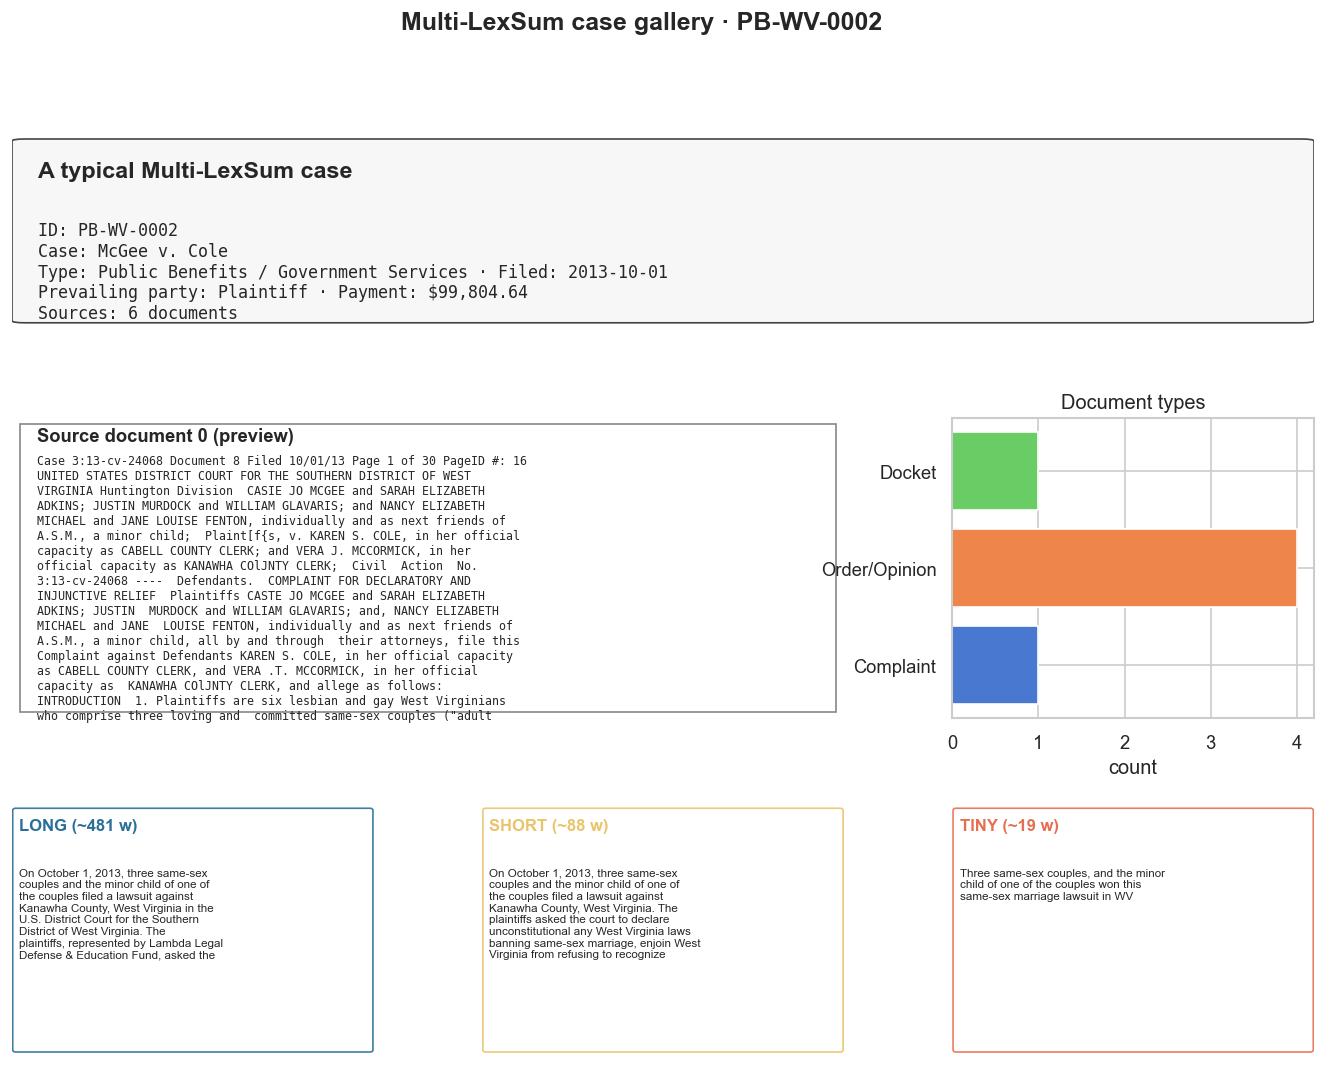

In [6]:
def render_case_gallery(ex, case_title="Sample case"):
    cm = ex.get("case_metadata") or {}
    fig = plt.figure(figsize=(14, 10))
    gs = fig.add_gridspec(3, 3, height_ratios=[0.8, 1.2, 1.0], hspace=0.35, wspace=0.3)

    ax0 = fig.add_subplot(gs[0, :])
    ax0.axis("off")
    meta_lines = [
        f"ID: {ex['id']}",
        f"Case: {cm.get('case_name', 'N/A')}",
        f"Type: {cm.get('case_type', 'N/A')} · Filed: {cm.get('filing_date', 'N/A')}",
        f"Prevailing party: {cm.get('prevailing_party', 'N/A')} · Payment: {cm.get('defendant_payment', 'N/A')}",
        f"Sources: {len(ex.get('sources') or [])} documents",
    ]
    ax0.text(0.02, 0.85, case_title, fontsize=14, fontweight="bold", va="top")
    ax0.text(0.02, 0.55, "\n".join(meta_lines), fontsize=10, va="top", family="monospace")
    ax0.add_patch(mpatches.FancyBboxPatch((0.01, 0.05), 0.98, 0.9, boxstyle="round,pad=0.01",
                                           linewidth=1, edgecolor="#444", facecolor="#f7f7f7"))

    ax1 = fig.add_subplot(gs[1, :2])
    ax1.axis("off")
    src0 = (ex.get("sources") or [""])[0]
    snippet = "\n".join(textwrap.wrap((src0 or "")[:1200], width=70)[:18])
    ax1.text(0.03, 0.97, "Source document 0 (preview)", fontsize=11, fontweight="bold", va="top")
    ax1.text(0.03, 0.88, snippet, fontsize=7, va="top", family="monospace")
    ax1.add_patch(mpatches.Rectangle((0.01, 0.02), 0.98, 0.96, fill=False, edgecolor="#888"))

    ax2 = fig.add_subplot(gs[1, 2])
    sm = sources_metadata_rows(ex)
    types = Counter(m.get("doc_type", "unknown") for m in sm)
    if types:
        ax2.barh(list(types.keys()), list(types.values()), color=sns.color_palette("muted"))
        ax2.set_title("Document types")
        ax2.set_xlabel("count")
    else:
        ax2.text(0.5, 0.5, "No sources_metadata", ha="center")

    for j, (sk, color) in enumerate([
        ("summary/long", "#2a6f97"),
        ("summary/short", "#e9c46a"),
        ("summary/tiny", "#e76f51"),
    ]):
        ax = fig.add_subplot(gs[2, j])
        ax.axis("off")
        text = ex.get(sk) or "(empty)"
        words = len(text.split()) if text != "(empty)" else 0
        label = sk.replace("summary/", "").upper()
        wrapped = "\n".join(textwrap.wrap(str(text)[:900], width=40)[:8])
        ax.text(0.02, 0.95, f"{label} (~{words} w)", fontsize=10, fontweight="bold", va="top", color=color)
        ax.text(0.02, 0.75, wrapped, fontsize=7, va="top")
        ax.add_patch(mpatches.FancyBboxPatch((0.01, 0.02), 0.98, 0.96, boxstyle="round,pad=0.008",
                                               linewidth=1, edgecolor=color, facecolor="white", alpha=0.9))

    fig.suptitle(f"Multi-LexSum case gallery · {ex['id']}", fontsize=15, fontweight="bold", y=0.98)
    fig.savefig(FIG / "gallery_sample_case.png", bbox_inches="tight", dpi=150)
    plt.show()

# Pick a case with all three summaries if possible
pick_idx = 0
for i in range(min(200, len(ds["train"]))):
    ex = ds["train"][i]
    if ex.get("summary/long") and ex.get("summary/short") and ex.get("summary/tiny"):
        pick_idx = i
        break
gallery_ex = ds["train"][pick_idx]
render_case_gallery(gallery_ex, case_title="A typical Multi-LexSum case")


---

## 4 · Corpus shape — how big is this benchmark?

The paper reports ~9,280 **summary instances**; Hugging Face stores **one row per case** with up to three summary fields. We inventory splits and missing targets.

,split,n_cases
0,train,3177
1,validation,454
2,test,908


,split,field,empty,present,pct_present
0,train,summary/long,0,3177,100.0
1,train,summary/short,967,2210,69.6
2,train,summary/tiny,2047,1130,35.6
3,validation,summary/long,0,454,100.0
4,validation,summary/short,142,312,68.7
5,validation,summary/tiny,293,161,35.5
6,test,summary/long,0,908,100.0
7,test,summary/short,292,616,67.8
8,test,summary/tiny,596,312,34.4


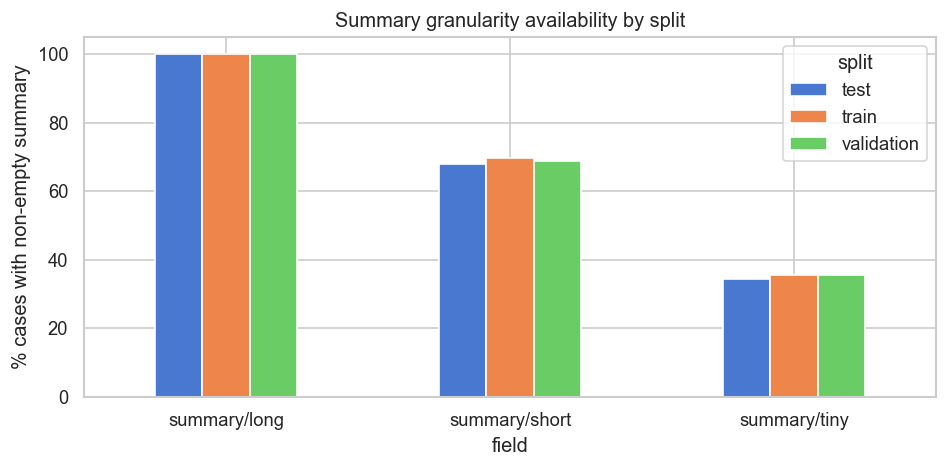

Unique case ids: 4539 · ids appearing in >1 row: 0


In [7]:
SUM_KEYS = ["summary/long", "summary/short", "summary/tiny"]
PAPER_TARGETS = {"summary/long": 650, "summary/short": 130, "summary/tiny": 25}

inv = pd.DataFrame([{"split": sn, "n_cases": len(ds[sn])} for sn in ds.keys()])
display(inv)
inv.to_csv(TAB / "split_inventory.csv", index=False)

# Missing / empty summaries
miss_rows = []
for sn in ds.keys():
    for sk in SUM_KEYS:
        col = ds[sn][sk]
        n_empty = sum(1 for x in col if not x or not str(x).strip())
        miss_rows.append({
            "split": sn,
            "field": sk,
            "empty": n_empty,
            "present": len(col) - n_empty,
            "pct_present": round(100 * (len(col) - n_empty) / len(col), 1),
        })
miss_df = pd.DataFrame(miss_rows)
display(miss_df)
miss_df.to_csv(TAB / "summary_availability.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
plot_miss = miss_df.pivot(index="field", columns="split", values="pct_present")
plot_miss.plot(kind="bar", ax=ax, rot=0)
ax.set_ylabel("% cases with non-empty summary")
ax.set_title("Summary granularity availability by split")
ax.legend(title="split")
plt.tight_layout()
fig.savefig(FIG / "summary_availability.png", dpi=150)
plt.show()

# Unique ids
all_ids = [(sn, ds[sn][i]["id"]) for sn in ds.keys() for i in range(len(ds[sn]))]
id_counts = Counter(i for _, i in all_ids)
dup_ids = [k for k, v in id_counts.items() if v > 1]
print(f"Unique case ids: {len(id_counts)} · ids appearing in >1 row: {len(dup_ids)}")


---

## 5 · Three summary granularities — length distributions

Expert targets (paper): **~650 / ~130 / ~25 words** for long / short / tiny. How close is the corpus?

count   mean  median    std  min   max     p95  \
split      field                                                           
test       summary/long     908  521.3   407.0  427.1   72  3883  1259.3   
           summary/short    616  111.4    97.0   58.8   26   671   204.2   
           summary/tiny     312   21.6    19.0    8.3    2    41    38.0   
train      summary/long    3177  550.8   419.0  489.6   65  8481  1426.0   
           summary/short   2210  112.9   100.0   59.8   19   620   220.1   
           summary/tiny    1130   21.0    19.0    8.2    2    43    37.0   
validation summary/long     454  558.8   448.5  483.5   87  3457  1409.0   
           summary/short    312  116.4   103.5   65.5   33   588   217.8   
           summary/tiny     161   21.7    19.0    8.0    8    43    38.0   

                          paper_target  
split      field                        
test       summary/long            650  
           summary/short           130  
           summary/tiny             25  
train      summary/long            650  
           summary/short           130  
           summary/tiny             25  
validation summary/long            650  
           summary/short           130  
           summary/tiny             25

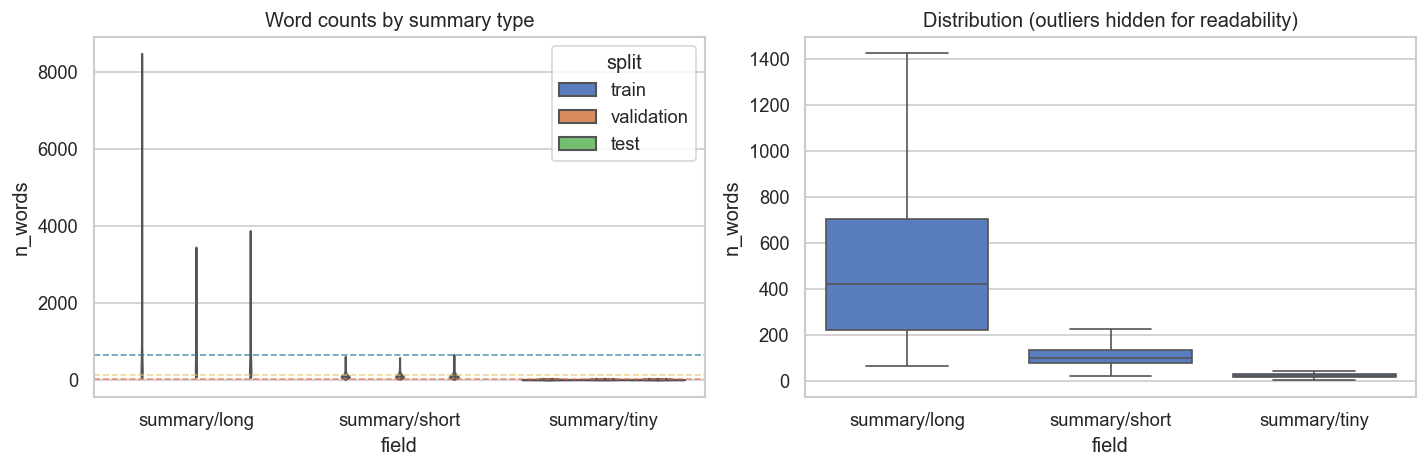

In [8]:
def word_len(t):
    return 0 if not t else len(str(t).split())


def collect_word_lengths():
    rows = []
    for sn in ds.keys():
        for sk in SUM_KEYS:
            for t in ds[sn][sk]:
                if t and str(t).strip():
                    rows.append({"split": sn, "field": sk, "n_words": word_len(t)})
    return pd.DataFrame(rows)


wl = collect_word_lengths()
stats = wl.groupby(["split", "field"])["n_words"].agg(["count", "mean", "median", "std", "min", "max",
                                                          lambda s: s.quantile(0.95)])
stats.columns = ["count", "mean", "median", "std", "min", "max", "p95"]
stats["paper_target"] = stats.index.get_level_values("field").map(PAPER_TARGETS)
display(stats.round(1))
stats.reset_index().to_csv(TAB / "summary_word_stats.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.violinplot(data=wl, x="field", y="n_words", hue="split", ax=axes[0], cut=0, inner="quart")
axes[0].axhline(650, color="#2a6f97", ls="--", lw=1, alpha=0.7)
axes[0].axhline(130, color="#e9c46a", ls="--", lw=1, alpha=0.7)
axes[0].axhline(25, color="#e76f51", ls="--", lw=1, alpha=0.7)
axes[0].set_title("Word counts by summary type")
sns.boxplot(data=wl, x="field", y="n_words", ax=axes[1], showfliers=False)
axes[1].set_title("Distribution (outliers hidden for readability)")
plt.tight_layout()
fig.savefig(FIG / "summary_words_violin.png", dpi=150)
plt.show()


---

## 6 · What happens if we **change the summary target**?

Tasks in the benchmark: **D→L**, **D→S**, **D→T** (documents → long/short/tiny). Switching granularity changes:

- **Compression ratio** (source words ÷ summary words)  
- **How many cases are usable** (missing short/tiny)  
- **Citation density** (citations per 100 words in expert text)

This matters for a thesis that may start with **long** summaries (richest citations) but later ablate to short/tiny.

n  median_compression  p95_compression  \
split      granularity                                              
test       long          908                56.7            232.7   
           short         616               388.9           2304.2   
           tiny          312              2267.3          16990.2   
train      long         3177                57.7            277.1   
           short        2210               382.4           2654.6   
           tiny         1130              2406.9          20156.3   
validation long          454                58.3            270.0   
           short         312               408.4           2499.7   
           tiny          161              2232.4          19480.2   

                        median_summary_words  
split      granularity                        
test       long                        407.0  
           short                        97.0  
           tiny                         19.0  
train      long                        419.0  
           short                       100.0  
           tiny                         19.0  
validation long                        448.5  
           short                       103.5  
           tiny                         19.0

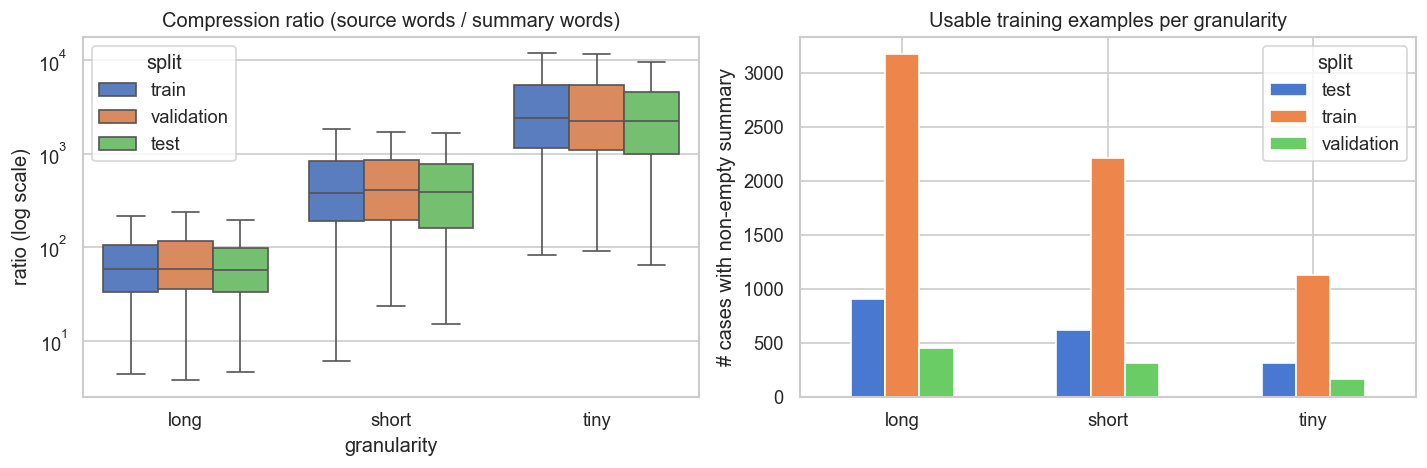

**Reading the chart:** Long summaries compress ~57× (median) vs ~2,357× for tiny — switching from **D→L** to **D→T** changes task difficulty and how much source text each output word represents.

In [9]:
def source_words(ex):
    return sum(len((s or "").split()) for s in (ex.get("sources") or []))


def build_granularity_table():
    rows = []
    for sn in ds.keys():
        split = ds[sn]
        for i in range(len(split)):
            ex = split[i]
            sw = source_words(ex)
            for sk in SUM_KEYS:
                text = ex.get(sk) or ""
                if not str(text).strip():
                    continue
                ww = word_len(text)
                rows.append({
                    "split": sn,
                    "id": ex["id"],
                    "granularity": sk.replace("summary/", ""),
                    "source_words": sw,
                    "summary_words": ww,
                    "compression": sw / max(ww, 1),
                })
    return pd.DataFrame(rows)


gran = build_granularity_table()
display(gran.groupby(["split", "granularity"]).agg(
    n=("id", "count"),
    median_compression=("compression", "median"),
    p95_compression=("compression", lambda s: s.quantile(0.95)),
    median_summary_words=("summary_words", "median"),
).round(1))

gran.to_csv(TAB / "granularity_compression.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=gran, x="granularity", y="compression", hue="split", ax=axes[0], showfliers=False)
axes[0].set_yscale("log")
axes[0].set_title("Compression ratio (source words / summary words)")
axes[0].set_ylabel("ratio (log scale)")

usable = miss_df.pivot(index="field", columns="split", values="present")
usable.index = [x.replace("summary/", "") for x in usable.index]
usable.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Usable training examples per granularity")
axes[1].set_ylabel("# cases with non-empty summary")
plt.tight_layout()
fig.savefig(FIG / "granularity_switch_analysis.png", dpi=150)
plt.show()

med_long = gran.loc[gran["granularity"] == "long", "compression"].median()
med_tiny = gran.loc[gran["granularity"] == "tiny", "compression"].median()
display(Markdown(
    f"**Reading the chart:** Long summaries compress ~{med_long:,.0f}× (median) vs ~{med_tiny:,.0f}× for tiny — "
    "switching from **D→L** to **D→T** changes task difficulty and how much source text each output word represents."
))


---

## 7 · Multi-document sources — structure behind each case

Each case concatenates **multiple** legal documents (complaints, orders, …). We measure document count, types, and OCR flags.

Source words — corpus-level:


n_sources                                        src_words  \
               count mean   std  min  25%  50%   75%    max     count   
split                                                                   
test           908.0  8.0   8.0  1.0  4.0  6.0   9.0  101.0     908.0   
train         3177.0  9.0  12.0  2.0  4.0  6.0  10.0  336.0    3177.0   
validation     454.0  9.0  10.0  2.0  4.0  6.0  11.0   92.0     454.0   

                     ...                     src_chars                       \
               mean  ...      75%        max     count      mean        std   
split                ...                                                      
test        53758.0  ...  56343.0  3022488.0     908.0  349799.0   876021.0   
train       62644.0  ...  62227.0  3565130.0    3177.0  406421.0   938398.0   
validation  69367.0  ...  69360.0  3068996.0     454.0  449561.0  1160367.0   

                                                              
                min      25%       50%       75%         max  
split                                                         
test        12612.0  55636.0  153538.0  364422.0  20262037.0  
train        6052.0  59470.0  160812.0  403912.0  23501994.0  
validation   7873.0  58802.0  161461.0  443210.0  19678889.0  

[3 rows x 24 columns]

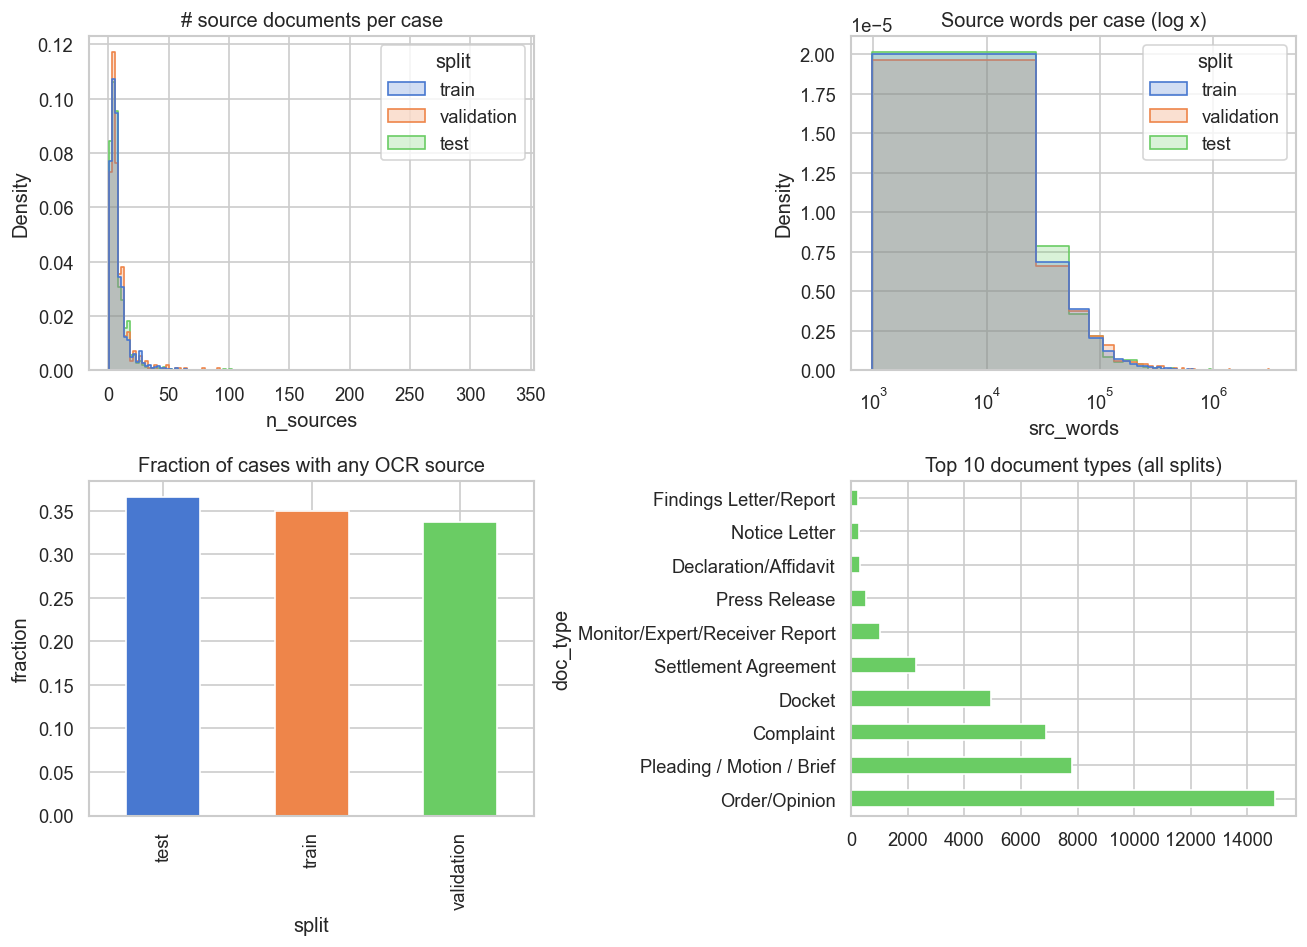

Mean source words per case (all splits): 61,539
Median: 24,546 · p95: 226,408


In [10]:
def per_case_source_features(ex):
    srcs = ex.get("sources") or []
    sm = sources_metadata_rows(ex)
    types = [m.get("doc_type", "unknown") for m in sm]
    return {
        "n_sources": len(srcs),
        "src_words": sum(len((s or "").split()) for s in srcs),
        "src_chars": sum(len(s or "") for s in srcs),
        "n_doc_types": len(set(types)) if types else 0,
        "any_ocr": any(m.get("is_ocr") for m in sm) if sm else False,
    }


src_frames = []
meta_types = []
for sn in ds.keys():
    for i in range(len(ds[sn])):
        ex = ds[sn][i]
        row = per_case_source_features(ex)
        row.update({"split": sn, "id": ex["id"]})
        src_frames.append(row)
        for m in sources_metadata_rows(ex):
            meta_types.append({"split": sn, "doc_type": m.get("doc_type", "unknown"),
                               "is_ocr": m.get("is_ocr", False)})

src_df = pd.DataFrame(src_frames)
src_df.to_csv(TAB / "source_stats_per_example.csv", index=False)

print("Source words — corpus-level:")
display(src_df.groupby("split")[["n_sources", "src_words", "src_chars"]].describe().round(0))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
sns.histplot(data=src_df, x="n_sources", hue="split", element="step", stat="density", ax=axes[0, 0], common_norm=False)
axes[0, 0].set_title("# source documents per case")
sns.histplot(data=src_df, x="src_words", hue="split", element="step", stat="density", ax=axes[0, 1], common_norm=False)
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Source words per case (log x)")
ocr_rate = src_df.groupby("split")["any_ocr"].mean()
ocr_rate.plot(kind="bar", ax=axes[1, 0], color=sns.color_palette("muted"))
axes[1, 0].set_title("Fraction of cases with any OCR source")
axes[1, 0].set_ylabel("fraction")
if meta_types:
    top_types = pd.DataFrame(meta_types)["doc_type"].value_counts().head(10)
    top_types.plot(kind="barh", ax=axes[1, 1], color=sns.color_palette("muted")[2])
    axes[1, 1].set_title("Top 10 document types (all splits)")
plt.tight_layout()
fig.savefig(FIG / "source_distributions.png", dpi=150)
plt.show()

# Paper claim: average > 75,000 words
mean_words = src_df["src_words"].mean()
print(f"Mean source words per case (all splits): {mean_words:,.0f}")
print(f"Median: {src_df['src_words'].median():,.0f} · p95: {src_df['src_words'].quantile(0.95):,.0f}")


---

## 8 · Extreme length & truncation — can a model “see” everything?

Literature and the Multi-LexSum paper stress **>75k words** and **200+ page** dockets. We audit what fraction of concatenated sources fits common context budgets.

**Local:** full-corpus tokenization (slow on CPU, ~30–60+ min). **Colab:** subsample of 800 cases per split.

=== Longest cases (by source words) ===


,split,id,n_sources,src_words
805,train,IM-HI-0004,336,3565130
3465,validation,PN-AZ-0003,92,3068996
4241,test,PN-MI-0001,97,3022488
575,train,IM-MD-0004,265,2906310
1993,train,PC-CA-0002,113,2332663
543,train,IM-CA-0002,98,1484162
3319,validation,JC-OR-0010,78,1376685
968,train,EE-NY-0260,30,1341831
47,train,IM-MI-0005,122,1314160
1407,train,PN-NM-0002,37,1272670


[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Truncation audit: subsample n≤800 per split


Tokenizing sources:   0%|          | 0/3 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (19584 > 1024). Running this sequence through the model will result in indexing errors


split,test,train,validation
budget,,,
2048,1.000,1.000,1.000
4096,0.999,0.994,0.991
8192,0.909,0.918,0.919
16384,0.721,0.755,0.731
32768,0.546,0.578,0.562
65536,0.350,0.389,0.403
131072,0.125,0.144,0.178


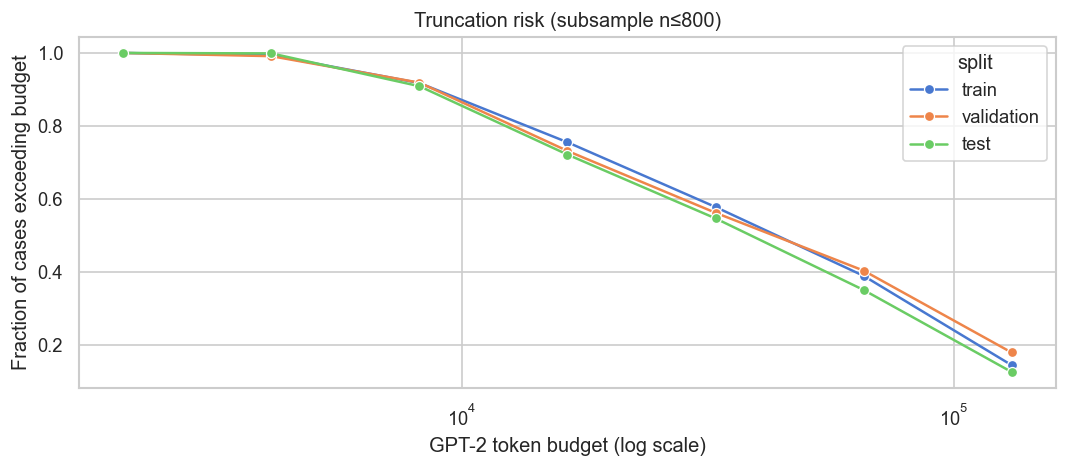

In [11]:
BUDGETS = [2048, 4096, 8192, 16384, 32768, 65536, 131072]

# Tail: longest cases
tail = src_df.nlargest(10, "src_words")[["split", "id", "n_sources", "src_words"]]
print("=== Longest cases (by source words) ===")
display(tail)

from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("gpt2")

def concat_sources(ex):
    return "\n\n".join(s or "" for s in (ex.get("sources") or []))

def count_gpt2_tokens(tok, text, src_words):
    """Token count for truncation audit; avoid hanging on 200+ page dockets."""
    if src_words > 80_000:
        return int(src_words * 1.33)
    t = text or ""
    if len(t) > 400_000:
        t = t[:200_000] + "\n\n" + t[-200_000:]
    return len(tok(t, add_special_tokens=False)["input_ids"])


def subsample_indices(n, cap):
    if cap is None:
        return np.arange(n)
    return np.arange(n) if n <= cap else RNG.choice(n, size=cap, replace=False)

trunc_label = f"subsample n≤{TOKEN_SUBSAMPLE}" if TOKEN_SUBSAMPLE else "full corpus"
print(f"Truncation audit: {trunc_label} per split")

trunc_rows = []
for sn in tqdm(ds.keys(), desc="Tokenizing sources"):
    idxs = subsample_indices(len(ds[sn]), TOKEN_SUBSAMPLE)
    for i in idxs:
        ex = ds[sn][int(i)]
        text = concat_sources(ex)
        sw = source_words(ex)
        n_tok = count_gpt2_tokens(tok, text, sw)
        row = {"split": sn, "id": ex["id"], "gpt2_tokens": n_tok, "src_words": sw}
        for B in BUDGETS:
            row[f"over_{B}"] = int(n_tok > B)
        trunc_rows.append(row)

trunc_df = pd.DataFrame(trunc_rows)
trunc_df.to_csv(TAB / "truncation_audit.csv", index=False)

frac = []
for sn in ds.keys():
    sub = trunc_df[trunc_df["split"] == sn]
    for B in BUDGETS:
        frac.append({"split": sn, "budget": B, "frac_over": sub[f"over_{B}"].mean()})
frac_df = pd.DataFrame(frac)
display(frac_df.pivot(index="budget", columns="split", values="frac_over").round(3))
frac_df.to_csv(TAB / "truncation_fractions.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(data=frac_df, x="budget", y="frac_over", hue="split", marker="o", ax=ax)
ax.set_xscale("log")
ax.set_xlabel("GPT-2 token budget (log scale)")
ax.set_ylabel("Fraction of cases exceeding budget")
ax.set_title(f"Truncation risk ({trunc_label})")
plt.tight_layout()
fig.savefig(FIG / "truncation_fractions.png", dpi=150)
plt.show()


---

## 9 · Legal metadata — what kinds of cases are these?

`case_metadata` encodes case type, filing year, prevailing party, causes of action, etc. This grounds **domain understanding** for summarization and later **citation verification**.

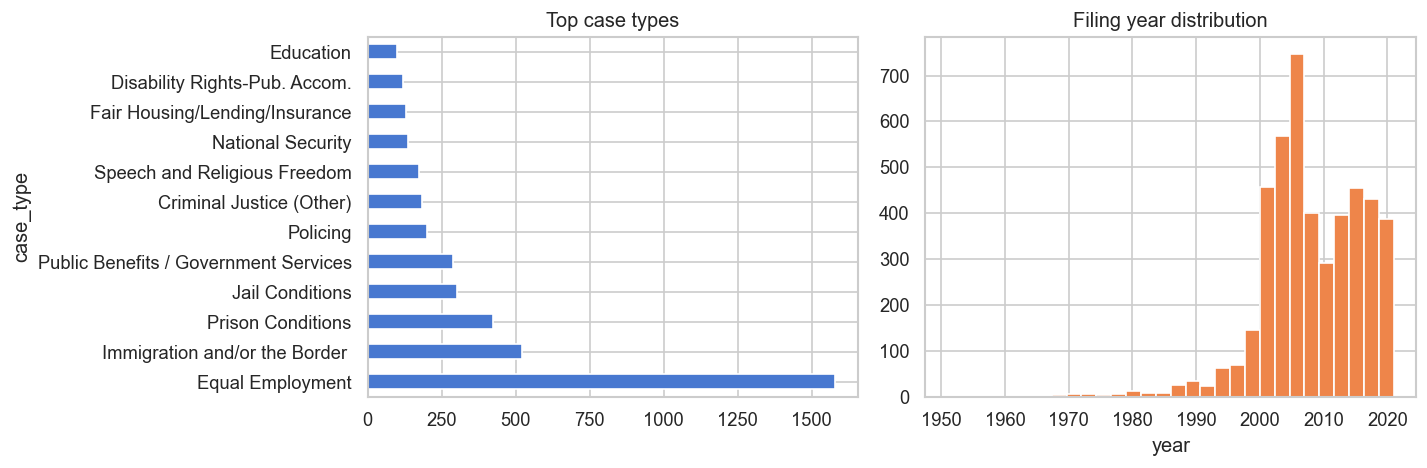

prevailing_party
Plaintiff          3143
Defendant           564
None Yet / None     535
Mixed               223
Unknown              74
Name: count, dtype: int64

In [12]:
meta_rows = []
for sn in ds.keys():
    for i in range(len(ds[sn])):
        cm = ds[sn][i].get("case_metadata") or {}
        meta_rows.append({
            "split": sn,
            "id": ds[sn][i]["id"],
            "case_type": cm.get("case_type") or "unknown",
            "filing_year": cm.get("filing_year") or "",
            "prevailing_party": cm.get("prevailing_party") or "unknown",
            "class_action_sought": cm.get("class_action_sought") or "",
        })
meta_df = pd.DataFrame(meta_rows)
meta_df.to_csv(TAB / "case_metadata_flat.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ct = meta_df["case_type"].value_counts().head(12)
ct.plot(kind="barh", ax=axes[0], color=sns.color_palette("muted")[0])
axes[0].set_title("Top case types")
fy = meta_df[meta_df["filing_year"].str.match(r"^\d{4}$", na=False)].copy()
fy["filing_year"] = fy["filing_year"].astype(int)
fy["filing_year"].hist(bins=30, ax=axes[1], color=sns.color_palette("muted")[1], edgecolor="white")
axes[1].set_title("Filing year distribution")
axes[1].set_xlabel("year")
plt.tight_layout()
fig.savefig(FIG / "metadata_landscape.png", dpi=150)
plt.show()

display(meta_df["prevailing_party"].value_counts().head(8))


---

## 10 · Citations in expert summaries — heuristic mining

Your thesis verifies **case citations** against CourtListener. Expert **long** summaries are the closest proxy for “what citations should look like” in gold text.

We use **regex heuristics** (reporter patterns, `v.`) — noisy but useful for distributions. Then an **optional** CourtListener spot-check on a small sample.

,count,mean,std,min,25%,50%,75%,max
field,,,,,,,,
summary/long,4539.0,1.41,4.06,0.0,0.0,0.0,2.0,172.0
summary/short,3138.0,0.10,0.39,0.0,0.0,0.0,0.0,6.0
summary/tiny,1603.0,0.02,0.15,0.0,0.0,0.0,0.0,2.0


field
summary/long     0.191
summary/short    0.069
summary/tiny     0.112
Name: cites_per_100_words, dtype: float64

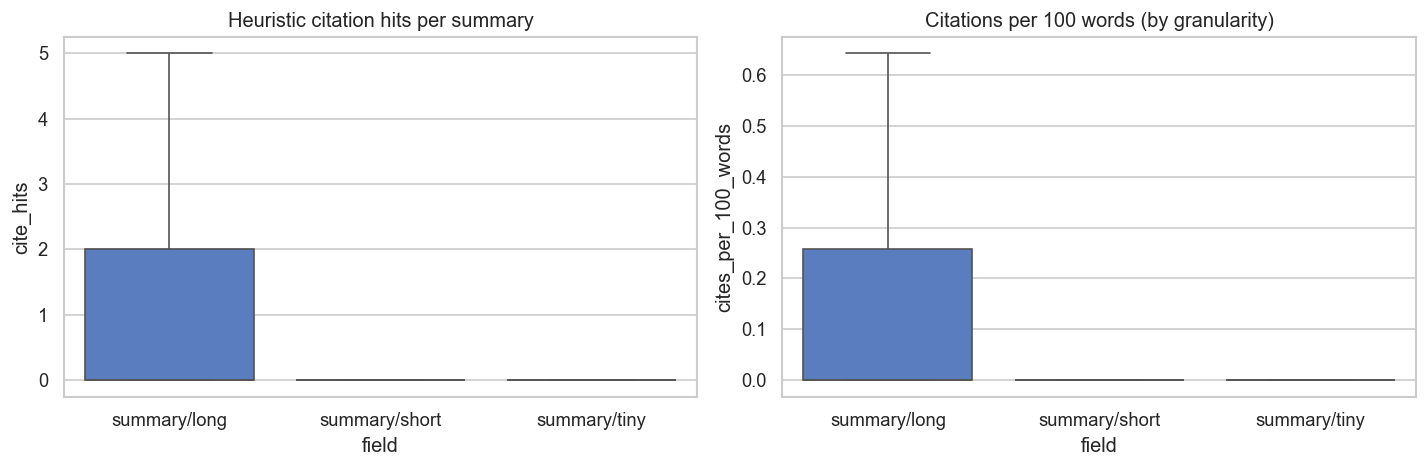

=== Random long-summary citation snippets ===

--- train[2444] id=EE-PR-0012 hits=0 ---
The Miami district office of the EEOC brought this suit against Lausell, Inc., a Puerto Rico corporation, in September 2006, in the U.S. District Court for the District of Puerto Rico.  The complaint alleged that Lausell had refused to make reasonable accommodations for an employee's diabetes, in violation of the Americans with Disabilities Act, and that Lausell fired the employee due to this disability.  In February 2008, the parties settled the case by entry of a consent decree.

The decree co…

--- train[2900] id=PC-IN-0019 hits=0 ---
On November 26, 2014, Prison Legal News (PLN), a project of the Human Rights Defense Center, filed this lawsuit under 42 U.S.C. § 1983 in the U.S. District Court for the Southern District of Indiana against the GEO Group, a Florida for-profit corporation that operates and manages the New Castle Correctional Facility, and the State of Indiana. The plaintiff, represen

In [13]:
CITE_PATTERNS = [
    ("F.Supp", re.compile(r"\b\d+\s+F\.\s?Supp\.?(?:\s*2d)?\s+\d+", re.I)),
    ("F.3d", re.compile(r"\b\d+\s+F\.\s?3d\s+\d+", re.I)),
    ("F.2d", re.compile(r"\b\d+\s+F\.\s?2d\s+\d+", re.I)),
    ("U.S.", re.compile(r"\b\d+\s+U\.S\.\s+\d+")),
    ("v_party", re.compile(r"\b[A-Z][A-Za-z0-9\.'\-]+\s+v\.\s+[A-Z]", re.I)),
]


def extract_citation_spans(text):
    if not text:
        return []
    spans = []
    for label, pat in CITE_PATTERNS:
        for m in pat.finditer(text):
            spans.append({"label": label, "span": m.group()})
    return spans


def cite_stats(text):
    spans = extract_citation_spans(text)
    return len(spans), spans


cite_rows = []
for sn in ds.keys():
    for sk in SUM_KEYS:
        for text in ds[sn][sk]:
            if not text or not str(text).strip():
                continue
            n, _ = cite_stats(text)
            ww = word_len(text)
            cite_rows.append({
                "split": sn,
                "field": sk,
                "cite_hits": n,
                "cites_per_100_words": 100 * n / max(ww, 1),
            })
cite_df = pd.DataFrame(cite_rows)
cite_df.to_csv(TAB / "citation_heuristic_all_granularities.csv", index=False)

display(cite_df.groupby(["field"])["cite_hits"].describe().round(2))
display(cite_df.groupby(["field"])["cites_per_100_words"].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=cite_df, x="field", y="cite_hits", ax=axes[0], showfliers=False)
axes[0].set_title("Heuristic citation hits per summary")
sns.boxplot(data=cite_df, x="field", y="cites_per_100_words", ax=axes[1], showfliers=False)
axes[1].set_title("Citations per 100 words (by granularity)")
plt.tight_layout()
fig.savefig(FIG / "citation_by_granularity.png", dpi=150)
plt.show()

# Show 5 random long-summary snippets with detected spans
print("=== Random long-summary citation snippets ===")
idxs = RNG.choice(len(ds["train"]), size=5, replace=False)
for i in idxs:
    t = ds["train"][int(i)]["summary/long"] or ""
    _, spans = cite_stats(t)
    print(f"\n--- train[{int(i)}] id={ds['train'][int(i)]['id']} hits={len(spans)} ---")
    print((t[:500] + "…") if len(t) > 500 else t)
    if spans:
        print("  detected:", [s["span"] for s in spans[:6]])


In [14]:
# Optional CourtListener API spot-check (set COURTLISTENER_TOKEN in Colab Secrets)
import urllib.parse
import urllib.request

CL_TOKEN = os.environ.get("COURTLISTENER_TOKEN", "")
SAMPLE_N = 15

if not CL_TOKEN:
    print("COURTLISTENER_TOKEN not set — skipping API spot-check.")
    print("Add token in Colab: Secrets → COURTLISTENER_TOKEN")
else:
    def courtlistener_search(query: str) -> dict:
        q = urllib.parse.quote(query[:200])
        url = f"https://www.courtlistener.com/api/rest/v4/search/?q={q}&type=o"
        req = urllib.request.Request(url, headers={"Authorization": f"Token {CL_TOKEN}"})
        with urllib.request.urlopen(req, timeout=20) as resp:
            return json.loads(resp.read().decode())

    # Collect candidate spans from random long summaries
    candidates = []
    idxs = RNG.choice(len(ds["train"]), size=SAMPLE_N, replace=False)
    for i in idxs:
        t = ds["train"][int(i)]["summary/long"] or ""
        _, spans = cite_stats(t)
        for s in spans[:2]:
            candidates.append({"row": int(i), "id": ds["train"][int(i)]["id"], "span": s["span"]})

    cl_rows = []
    for c in candidates[:20]:
        try:
            res = courtlistener_search(c["span"])
            n = res.get("count", 0)
            cl_rows.append({**c, "cl_count": n, "status": "ok" if n else "not_found"})
        except Exception as e:
            cl_rows.append({**c, "cl_count": None, "status": f"error: {e}"})
    cl_df = pd.DataFrame(cl_rows)
    display(cl_df)
    cl_df.to_csv(TAB / "courtlistener_spotcheck.csv", index=False)
    hit_rate = (cl_df["cl_count"].fillna(0) > 0).mean()
    print(f"Spot-check hit rate (count>0): {hit_rate:.1%} on {len(cl_df)} spans")


COURTLISTENER_TOKEN not set — skipping API spot-check.
Add token in Colab: Secrets → COURTLISTENER_TOKEN


---

## 11 · Data quality & anomalies

In [15]:
anom = []
for sn in ds.keys():
    d = ds[sn]
    for sk in SUM_KEYS:
        anom.append({"split": sn, "check": f"empty_{sk}", "count": sum(1 for x in d[sk] if not x or not str(x).strip())})
    anom.append({"split": sn, "check": "empty_sources_list", "count": sum(1 for s in d["sources"] if len(s) == 0)})
    anom.append({"split": sn, "check": "zero_len_source_doc", "count": sum(
        1 for s in d["sources"] for doc in (s or []) if doc is not None and len(doc) == 0
    )})
anom_df = pd.DataFrame(anom)
display(anom_df)
anom_df.to_csv(TAB / "anomalies_empty.csv", index=False)

# Stratified spot-check indices for manual review (internal; CC BY-NC)
train_d = ds["train"]
wl = np.array([word_len(t) for t in train_d["summary/long"]])
q1, q2 = np.quantile(wl, [1/3, 2/3])
buckets = {
    "short_summary": np.where(wl <= q1)[0],
    "mid_summary": np.where((wl > q1) & (wl <= q2))[0],
    "long_summary": np.where(wl > q2)[0],
}
samples = []
for name, idxs in buckets.items():
    pick = RNG.choice(idxs, size=min(5, len(idxs)), replace=False) if len(idxs) else []
    for i in pick:
        samples.append({"bucket": name, "row": int(i), "id": train_d[int(i)]["id"]})
pd.DataFrame(samples).to_csv(REPORTS / "sample_indices.csv", index=False)
print("Wrote stratified sample_indices.csv for manual review")


,split,check,count
0,train,empty_summary/long,0
1,train,empty_summary/short,967
2,train,empty_summary/tiny,2047
3,train,empty_sources_list,0
4,train,zero_len_source_doc,0
5,validation,empty_summary/long,0
6,validation,empty_summary/short,142
7,validation,empty_summary/tiny,293
8,validation,empty_sources_list,0
9,validation,zero_len_source_doc,0


Wrote stratified sample_indices.csv for manual review


---

## 12 · So what? — tying EDA to the thesis pipeline

| EDA finding | Implication for generate → verify → correct |
|-------------|-----------------------------------------------|
| **Long sources, heavy tails** | Neural Module A will truncate or chunk; faithfulness risk rises — verification cannot fix what the model never saw. |
| **Three granularities, uneven availability** | Start evaluation on **D→L** (all cases); short/tiny ablations drop usable N. |
| **High compression at long granularity** | More abstraction → more citation hallucination risk (paper human score ~0.43/3 for models). |
| **Citations denser in long summaries** | Citation extraction + CourtListener (Module B/C) most informative on **long** targets first. |
| **Heuristic ≠ ground truth** | Manual audit subset (~200 summaries) still needed to calibrate HR taxonomy (RQ1). |
| **OCR / heterogeneous doc types** | Noisy inputs → extractor errors; symbolic verifier must return **Ambiguous**, not guess. |

**Proposed next steps (not executed here):** baseline PRIMERA/long-context summarizer → citation extractor → CourtListener verifier → bounded correction loop on **validation** split.

---

## 13 · Export artifacts

Figures → `reports/figures/` · Tables → `reports/tables/`  

Download from Colab: `Files` panel, or zip below.

In [16]:
# Zip reports (auto-download in Colab only)
import zipfile
zip_path = WORK / "multilexsum_eda_reports.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in (FIG, TAB):
        for f in folder.rglob("*"):
            if f.is_file():
                zf.write(f, f.relative_to(WORK))
print("Exported:", zip_path.resolve())
print("Figures:", sorted(p.name for p in FIG.glob("*.png")))
print("Tables:", sorted(p.name for p in TAB.glob("*.csv")))

if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))
else:
    print("Local: open reports/figures/ and reports/tables/ in Finder or your IDE.")


Exported: /Users/rajakarthikchirumamilla/Desktop/Thesis/code/multilexsum_eda_reports.zip
Figures: ['citation_by_granularity.png', 'gallery_sample_case.png', 'granularity_switch_analysis.png', 'metadata_landscape.png', 'source_distributions.png', 'summary_availability.png', 'summary_words_violin.png', 'truncation_fractions.png']
Tables: ['anomalies_empty.csv', 'case_metadata_flat.csv', 'citation_heuristic_all_granularities.csv', 'granularity_compression.csv', 'source_stats_per_example.csv', 'split_inventory.csv', 'summary_availability.csv', 'summary_word_stats.csv', 'truncation_audit.csv', 'truncation_fractions.csv']
Local: open reports/figures/ and reports/tables/ in Finder or your IDE.
